## Задание
Продолжаем работать с объединенным датасетом merged_data

**Задача 1**

Цель: выделить пользователей, которые делают упор на индивидуальные тренировки.

Что сделать:
Выберите пользователей, у которых >70% тренировок — индивидуальные.
Для этих пользователей:
+ Посчитайте средний чек;
+ Посчитайте среднее число тренировок в месяц;
+ Разбейте их по городам и полу.

Вопросы для анализа:

+ Кто чаще выбирает индивидуальные тренировки?
+ Есть ли зависимость от пола или города?
+ Насколько высок средний чек у таких пользователей?

**Задача 2.**
Найдите 10 пользователей с наибольшим общим количеством посещений (групповые + индивидуальные тренировки) за весь период наблюдения.

Что нужно сделать:

+ Рассчитайте общее количество тренировок для каждого пользователя.

+ Определите 10 самых активных пользователей и сохраните их идентификаторы в виде списка.

Постройте распределение этих пользователей по:

+ городу
+ полу

Вопросы для анализа:
+ В каких городах больше всего супер-активных клиентов?
+ Какого они пола?

**Задача 3**
Ваша цель — проанализировать, как менялась клиентская база по месяцам:
сколько клиентов приходило, сколько уходило и сколько оставалось активными.

Шаги:
+ Новые клиенты — это те, у кого первый месяц появления (минимальный mon в данных).

+ Ушедшие клиенты — это те, у кого последний месяц активности (максимальный mon в данных).

+ Активные клиенты — это те, кто был активен в конкретном месяце.

Что нужно сделать:
Рассчитайте три метрики для каждого месяца:
+ new_clients: количество клиентов, для которых этот месяц — первый.
+ gone_clients: количество клиентов, для которых этот месяц — последний.
+ active_clients: общее количество уникальных клиентов в этом месяце.

Для этого:
Создайте три отдельных датафрейма:

+ с новыми клиентами по месяцам,
+ с ушедшими клиентами по месяцам,
+ с активными клиентами по месяцам.

Объедините их по полю mon.

Постройте линейный график с тремя линиями.

Подсказка:
+ Используйте groupby и nunique() для подсчёта количества клиентов.
+ Для объединения датафреймов — merge.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# загружаем очищенный датасет
df = pd.read_csv('merged_data.csv')
df.head(3)

,id_user,mon,cnt_group,cnt_indiv,sum_group,sum_indiv,cnt_total,sum_total,min_mon,max_mon,city,age,gender
0,1000,2023-03,0,2,0,3600,2,3600,2023-03,2023-12,СПб,44.0,female
1,1000,2023-04,0,4,0,7200,4,7200,2023-03,2023-12,СПб,44.0,female
2,1000,2023-05,0,4,0,6400,4,6400,2023-03,2023-12,СПб,44.0,female


### Задача 1. Пользователи с 70%+ инд.тренировок

In [5]:
user_stats = df.groupby('id_user').agg(
    total_cnt=('cnt_total', 'sum'),
    total_indiv=('cnt_indiv', 'sum'),
    total_sum=('sum_total', 'sum'),
    months_count=('mon', 'nunique'),
    city=('city', 'first'),
    gender=('gender', 'first')
).reset_index()

user_stats['indiv_share'] = user_stats['total_indiv'] / user_stats['total_cnt']
indiv_users = user_stats[user_stats['indiv_share'] > 0.7].copy()

print(f"Количество пользователей с >70% индивидуальных тренировок: {len(indiv_users)}")

indiv_users['avg_check_per_month'] = indiv_users['total_sum'] / indiv_users['months_count']
indiv_users['avg_cnt_per_month'] = indiv_users['total_cnt'] / indiv_users['months_count']

final_stats = indiv_users.groupby(['city', 'gender']).agg(
    avg_check=('avg_check_per_month', 'mean'),
    avg_cnt=('avg_cnt_per_month', 'mean')
).reset_index()

print("\nСредние показатели по городам и полу (в расчете на клиента):")
print(final_stats)

print(f"\nОбщий средний чек в месяц: {indiv_users['avg_check_per_month'].mean():.2f} руб.")
print(f"Общее среднее число тренировок в месяц: {indiv_users['avg_cnt_per_month'].mean():.2f}")

print("\nКоличество пользователей по городам и полу:")
print(indiv_users.groupby(['city', 'gender']).size().reset_index(name='count'))

Количество пользователей с >70% индивидуальных тренировок: 281

Средние показатели по городам и полу (в расчете на клиента):
           city  gender    avg_check   avg_cnt
0  Екатеринбург  female  5391.746032  3.009524
1  Екатеринбург    male  5832.394180  3.256184
2        Казань  female  6297.500000  3.756250
3        Казань    male  5229.378307  2.931548
4        Москва  female  5565.425624  3.141311
5        Москва    male  6915.316115  3.872733
6           СПб  female  6093.278770  3.399777
7           СПб    male  5024.889456  2.821443

Общий средний чек в месяц: 5865.58 руб.
Общее среднее число тренировок в месяц: 3.30

Количество пользователей по городам и полу:
           city  gender  count
0  Екатеринбург  female     12
1  Екатеринбург    male     12
2        Казань  female      8
3        Казань    male     12
4        Москва  female    118
5        Москва    male     59
6           СПб  female     32
7           СПб    male     28


### Задача 2. Топ-10 клиентов

In [6]:
total_workouts = df.groupby('id_user').agg(
    total_visits=('cnt_total', 'sum'),
    city=('city', 'first'),
    gender=('gender', 'first')
).reset_index()

top_10 = total_workouts.sort_values('total_visits', ascending=False).head(10)
top_10_ids = top_10['id_user'].tolist()

print(f"Топ-10 ID пользователей: {top_10_ids}")

print("\nРаспределение топ-10 по городам:")
print(top_10.groupby('city').size().reset_index(name='count'))

print("\nРаспределение топ-10 по полу:")
print(top_10.groupby('gender').size().reset_index(name='count'))

Топ-10 ID пользователей: [1381, 1013, 1657, 1506, 1929, 1570, 1001, 1002, 1194, 1582]

Распределение топ-10 по городам:
           city  count
0  Екатеринбург      2
1        Москва      6
2           СПб      2

Распределение топ-10 по полу:
   gender  count
0  female      4
1    male      6


### Задача 3. Динамика клиентской базы

        mon  new_clients  gone_clients  active_clients
0   2023-01          337            15             337
1   2023-02           88            22             350
2   2023-03           83            37             355
3   2023-04           62            21             345
4   2023-05           57            21             360
5   2023-06           51            13             383
6   2023-07           48            33             412
7   2023-08           35            33             423
8   2023-09           28            55             429
9   2023-10           27           101             441
10  2023-11           10           130             399
11  2023-12           12           357             357


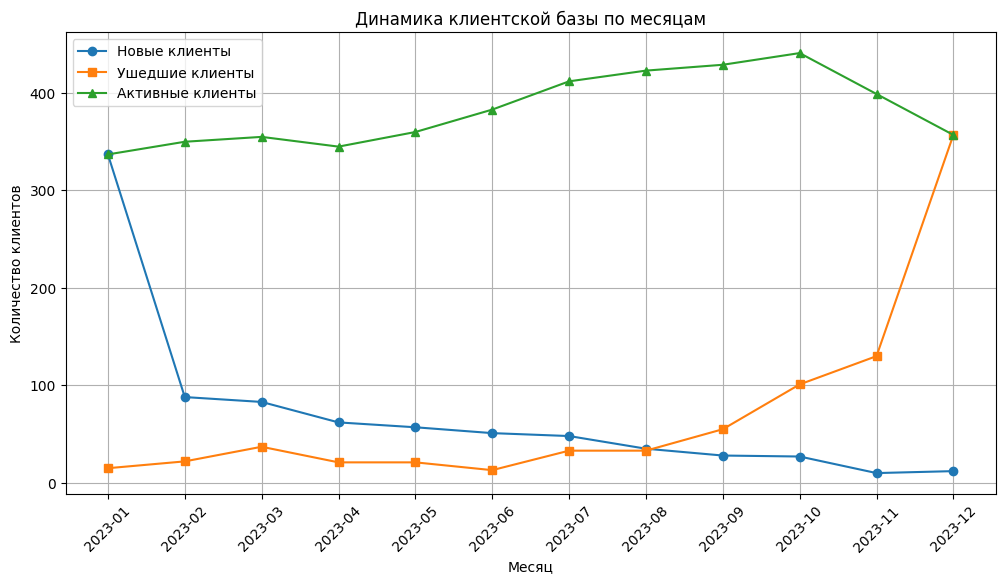

In [7]:
new_clients = df.groupby('id_user')['mon'].min().reset_index()
new_clients_count = new_clients.groupby('mon').size().reset_index(name='new_clients')

gone_clients = df.groupby('id_user')['mon'].max().reset_index()
gone_clients_count = gone_clients.groupby('mon').size().reset_index(name='gone_clients')

active_clients_count = df.groupby('mon')['id_user'].nunique().reset_index(name='active_clients')

dynamics = new_clients_count.merge(gone_clients_count, on='mon', how='outer').merge(active_clients_count, on='mon', how='outer')
dynamics = dynamics.sort_values('mon').fillna(0)

print(dynamics)

plt.figure(figsize=(12, 6))

plt.plot(dynamics['mon'], dynamics['new_clients'], marker='o', label='Новые клиенты')
plt.plot(dynamics['mon'], dynamics['gone_clients'], marker='s', label='Ушедшие клиенты')
plt.plot(dynamics['mon'], dynamics['active_clients'], marker='^', label='Активные клиенты')

plt.title('Динамика клиентской базы по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество клиентов')
plt.xticks(rotation=45)
plt.grid()
plt.legend()
plt.show()